<div dir="rtl" style="text-align: right;">
تحلیل دیتاست تایتانیک از کتابخانه seaborn
<div>


In [150]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

In [151]:
df = sns.load_dataset("titanic")

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [152]:
df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [153]:
print(df.describe())


         survived      pclass         age       sibsp       parch        fare
count  891.000000  891.000000  714.000000  891.000000  891.000000  891.000000
mean     0.383838    2.308642   29.699118    0.523008    0.381594   32.204208
std      0.486592    0.836071   14.526497    1.102743    0.806057   49.693429
min      0.000000    1.000000    0.420000    0.000000    0.000000    0.000000
25%      0.000000    2.000000   20.125000    0.000000    0.000000    7.910400
50%      0.000000    3.000000   28.000000    0.000000    0.000000   14.454200
75%      1.000000    3.000000   38.000000    1.000000    0.000000   31.000000
max      1.000000    3.000000   80.000000    8.000000    6.000000  512.329200


In [154]:
df.isna()

df.isna().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [155]:
df.duplicated().sum()

107

In [156]:
df.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone'],
      dtype='object')

In [157]:
df["class"].value_counts()


class
Third     491
First     216
Second    184
Name: count, dtype: int64

In [158]:
df["deck"].value_counts()


deck
C    59
B    47
D    33
E    32
A    15
F    13
G     4
Name: count, dtype: int64

# Age

<div dir="rtl" style="
    text-align: right;
    font-size: 20px;
    line-height: 2;
    font-family: Tahoma;
">
بررسی اطلاعات اولیه شامب میانگین و میانه و مد
<div>

In [159]:
male_age = df[df['sex'] == "male"]['age']

print("Male Mean:", male_age.mean())
print("Male Mode:", male_age.mode())
print("Male Median:", male_age.median())

Male Mean: 30.72664459161148
Male Mode: 0    19.0
1    25.0
2    28.0
Name: age, dtype: float64
Male Median: 29.0


In [160]:
female_age = df[df['sex'] == "female"]['age']

print("Female Mean:", female_age.mean())
print("Female Mode:", female_age.mode())
print("Female Median:", female_age.median())

Female Mean: 27.915708812260537
Female Mode: 0    24.0
Name: age, dtype: float64
Female Median: 27.0


<div dir="rtl" style="
    text-align: right;
    font-size: 20px;
    line-height: 2;
    font-family: Tahoma;
">
بررسی و رسم هستوگرام بر حسب سن و تعداد افراد
براساس این نمودار بیشترین افراد در بازه بین 20-30 سال بوده
<div>

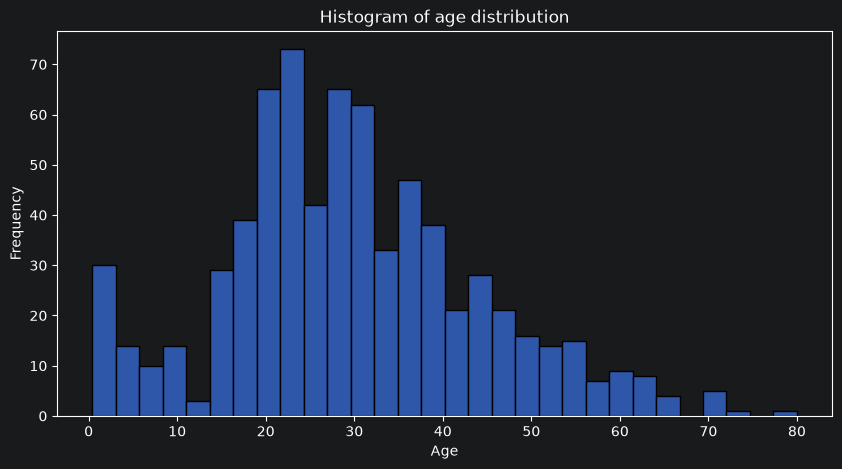

In [161]:
plt.figure(figsize=(10, 5))

sns.histplot(df, x="age", bins=30, edgecolor="black")

plt.title("Histogram of age distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()


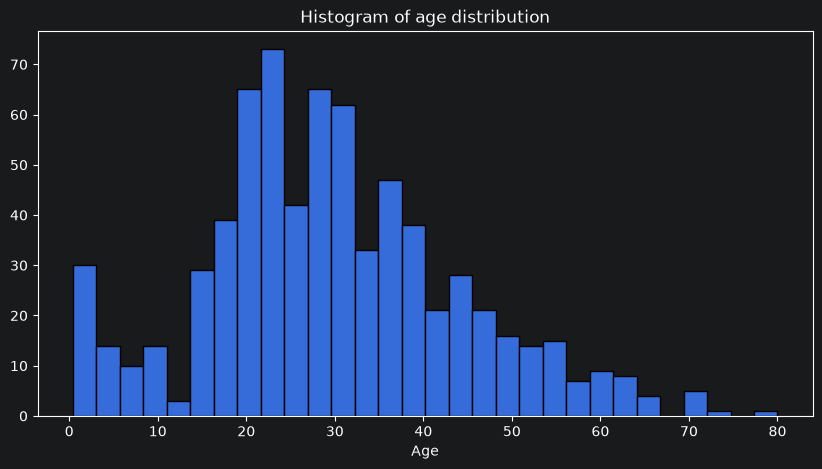

In [162]:
plt.figure(figsize=(10, 5))
plt.hist(df["age"], bins=30, edgecolor="black")
plt.title("Histogram of age distribution")
plt.xlabel("Age")
plt.show()

<div dir="rtl" style="
    text-align: right;
    font-size: 20px;
    line-height: 2;
    font-family: Tahoma;
">
بررسی سن بر حسب زنده موندن افراد
بر حسب این نمودار در بازه بالا 60 سال افراد کمتری زنده موندن
<div>

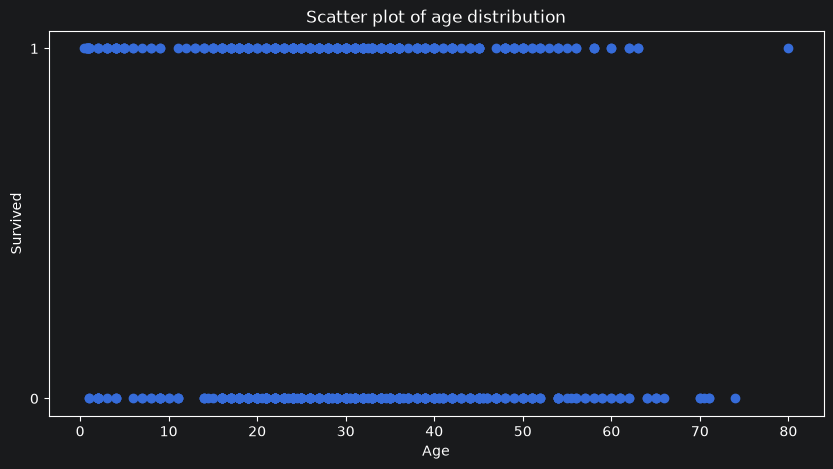

In [163]:
plt.figure(figsize=(10, 5))

plt.scatter(df["age"], df["survived"])
plt.title("Scatter plot of age distribution")
plt.xlabel("Age")
plt.ylabel("Survived")
plt.yticks([0, 1])

plt.show()


# sex

<div dir="rtl" style="
    text-align: right;
    font-size: 20px;
    line-height: 2;
    font-family: Tahoma;
">
بررسی درصدی زنده ماندن مردان نسبت به زنان
بر اساس این تحلیل و پلات حدودا زنان دوبرابر آقایون بوده اند
<div>

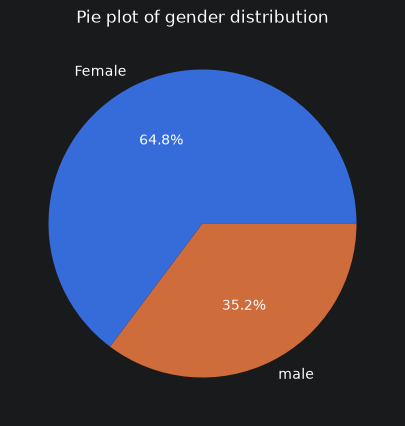

In [164]:
survived = df[df["survived"] == 1]
gender_count = df["sex"].value_counts()

plt.figure(figsize=(10, 5))

plt.pie(gender_count, labels=["Female", "male"], autopct="%1.1f%%")
plt.title("Pie plot of gender distribution")
plt.show()

<div dir="rtl" style="
    text-align: right;
    font-size: 20px;
    line-height: 2;
    font-family: Tahoma;
">
مقایسه عددی بین تعداد زنان و مردان حاضر در کشتی یه نسان دهنده بیشتر بودن تعداد اقایون هستش
<div>

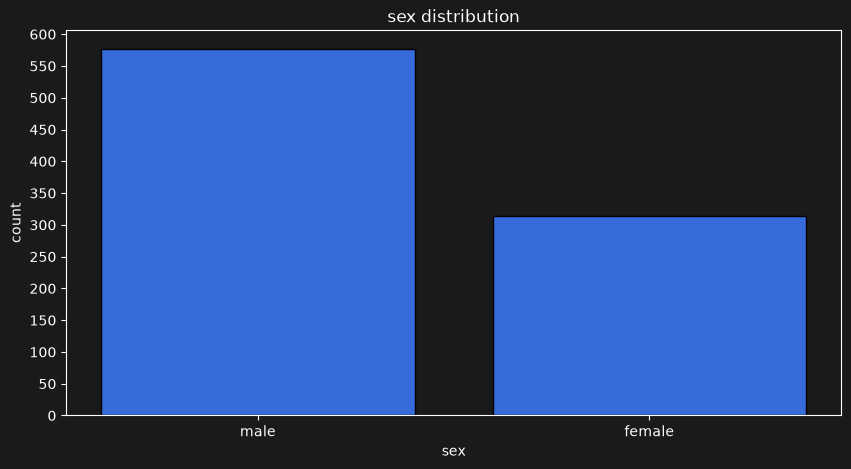

In [165]:
plt.figure(figsize=(10, 5))
gender_count = df["sex"].value_counts()
plt.bar(gender_count.index, gender_count.values, edgecolor="black")
plt.title("sex distribution")
plt.xlabel("sex")
plt.ylabel("count")
plt.yticks(range(0, 650, 50))
plt.show()

<div dir="rtl" style="
    text-align: right;
    font-size: 20px;
    line-height: 2;
    font-family: Tahoma;
">
بررسی درصد زنان و مردان در انواع نوع بلیط های کشتی نکته قابل توجه بیشتر بودن درصد مردان به زنان در بلیط درجه 3 هستش

<div>

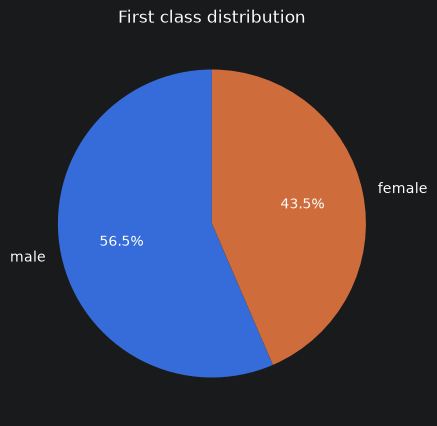

In [166]:
first_class = df[df["pclass"] == 1]["sex"].value_counts()

plt.figure(figsize=(10, 5))
plt.pie(
    first_class,
    labels=first_class.index,
    autopct="%1.1f%%",
    startangle=90,
)

plt.title("First class distribution")
plt.show()


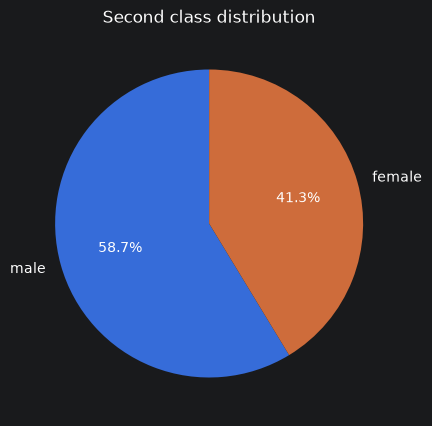

In [167]:
second_class = df[df["pclass"] == 2]["sex"].value_counts()

plt.figure(figsize=(10, 5))
plt.pie(
    second_class,
    labels=second_class.index,
    autopct="%1.1f%%",
    startangle=90,
)

plt.title("Second class distribution")
plt.show()


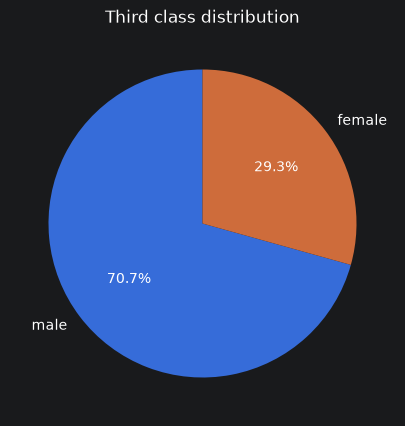

In [168]:
third_class = df[df["pclass"] == 3]["sex"].value_counts()

plt.figure(figsize=(10, 5))
plt.pie(
    third_class,
    labels=third_class.index,
    autopct="%1.1f%%",
    startangle=90,
)

plt.title("Third class distribution")
plt.show()


<div dir="rtl" style="
    text-align: right;
    font-size: 20px;
    line-height: 2;
    font-family: Tahoma;
">
بررسی تعداد زنان و مردان نجات یافته بر روی نمودار نشان میدهد حدودا زنان 2 برابر مردان نجات یافته اند

<div>

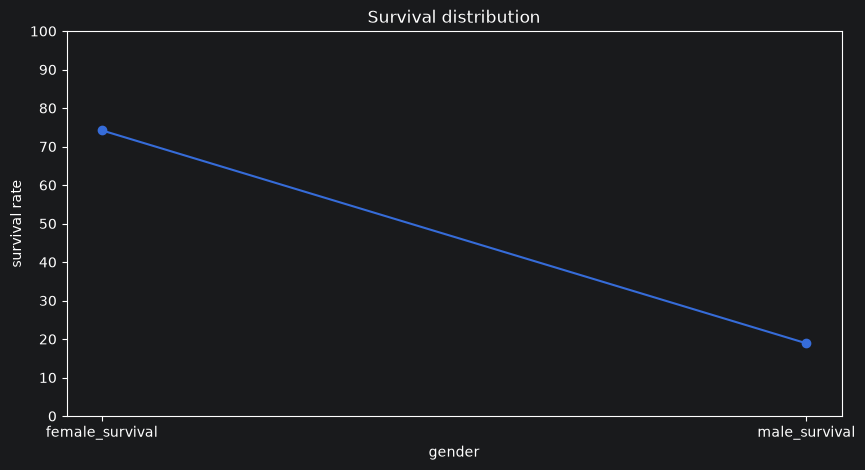

In [169]:
female_survival = df[df["sex"] == "female"]["survived"].mean() * 100
male_survival = df[df["sex"] == "male"]["survived"].mean() * 100

plt.figure(figsize=(10, 5))
plt.plot(
    ["female_survival", "male_survival"],
    [female_survival, male_survival],
    marker="o",

)
plt.title("Survival distribution")
plt.xlabel("gender")
plt.ylabel("survival rate")
plt.yticks(range(0, 101, 10))
plt.show()


# survived

<div dir="rtl" style="
    text-align: right;
    font-size: 20px;
    line-height: 2;
    font-family: Tahoma;
">
بررسی تعداد افراد نجات یافته مانده
<div>

In [170]:
survived_counts = df["survived"].value_counts()

survived_counts



survived
0    549
1    342
Name: count, dtype: int64

<div dir="rtl" style="
    text-align: right;
    font-size: 20px;
    line-height: 2;
    font-family: Tahoma;
">
بر اساس این نمودار بیش از 50 درصد افراد در این حادثه جون خودشونو از دست دادن
<div>

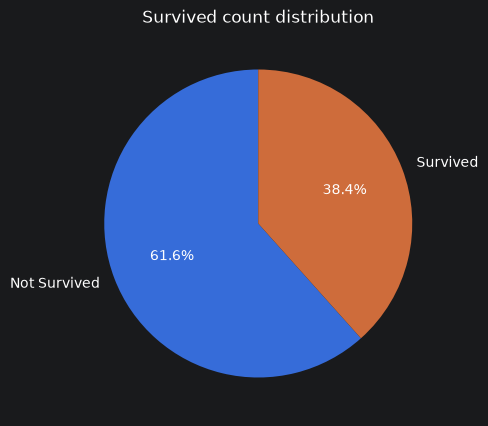

In [171]:
plt.figure(figsize=(10, 5))

plt.pie(
    survived_counts,
    labels=["Not Survived", "Survived"],
    autopct="%1.1f%%",
    startangle=90,
)
plt.title("Survived count distribution")
plt.show()

In [172]:
first_class = df[df["pclass"] == 1]["survived"].mean() * 100
second_class = df[df["pclass"] == 2]["survived"].mean() * 100
third_class = df[df["pclass"] == 3]["survived"].mean() * 100

print(f"first_class:{first_class}\n, second_class:{second_class}\n, third_class:{third_class}")

first_class:62.96296296296296
, second_class:47.28260869565217
, third_class:24.236252545824847


<div dir="rtl" style="
    text-align: right;
    font-size: 20px;
    line-height: 2;
    font-family: Tahoma;
">
نمودار نرخ زنده ماندن مسافران بر اساس کلاس بلیت نشان می‌دهد که کلاس سفر ارتباط قابل‌توجهی با احتمال زنده ماندن داشته است. مسافران کلاس اول با نرخ بقای تقریبی ۶۳ درصد بیشترین میزان نجات را داشته‌اند، درحالی‌که این مقدار برای کلاس دوم حدود ۴۷ درصد و برای کلاس سوم حدود ۲۴ درصد بوده است. این نتایج نشان می‌دهد که مسافران کلاس‌های بالاتر از شانس بیشتری برای زنده ماندن برخوردار بوده‌اند.
<div>

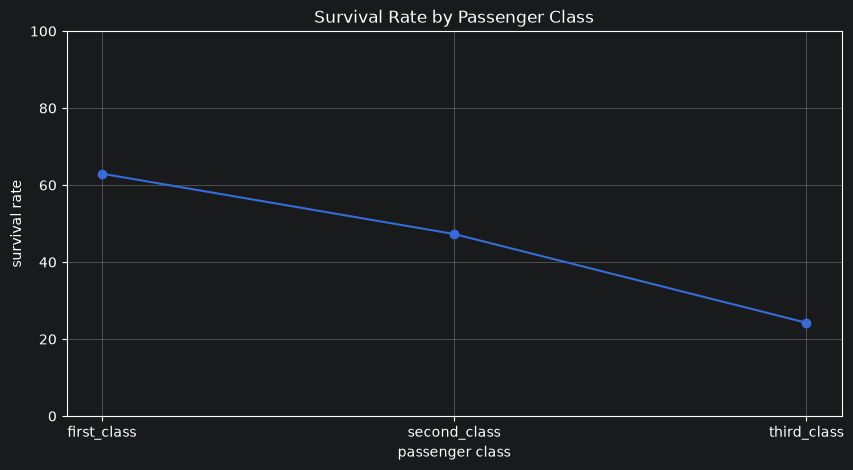

In [173]:
plt.figure(figsize=(10, 5))

plt.plot(
    ["first_class", "second_class", "third_class"],
    [first_class, second_class, third_class],
    marker="o",
)

plt.title("Survival Rate by Passenger Class")
plt.xlabel("passenger class")
plt.ylabel("survival rate")
plt.ylim(0, 100)
plt.grid()
plt.show()

# Fare

<div dir="rtl" style="
    text-align: right;
    font-size: 20px;
    line-height: 2;
    font-family: Tahoma;
">
بررسی قیمت بلیط ها
<div>

In [174]:
df["fare"].describe()


count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: fare, dtype: float64

In [175]:
df["fare"].isna().sum()

0

<div dir="rtl" style="
    text-align: right;
    font-size: 20px;
    line-height: 2;
    font-family: Tahoma;
">
بررسی آماری بلیط ها شامل میانگین و میانه و مد و انحراف معیار
<div>

In [176]:
fare_max = df["fare"].max()
fare_min = df["fare"].min()
fare_mean = df["fare"].mean()
fare_median = df["fare"].median()
fare_mode = df["fare"].mode()
fare_std = df["fare"].std()

lower_bound = fare_mean - fare_std * 2
upper_bound = fare_mean + fare_std * 2
print(f"max:{fare_max}\n,min:{fare_min}\n,mean:{fare_mean}\n,media:{fare_median}\n,mode:{fare_mode}\n,std:{fare_std}")


max:512.3292
,min:0.0
,mean:32.204207968574636
,media:14.4542
,mode:0    8.05
Name: fare, dtype: float64
,std:49.6934285971809


<div dir="rtl" style="
    text-align: right;
    font-size: 20px;
    line-height: 2;
    font-family: Tahoma;
">
بررسی حد بالا و حد پایین برای پیدا کردن داده های خارج از عرف
<div>

In [177]:
out_lier = df[
    (df["fare"] > upper_bound) | (df["fare"] < lower_bound)
    ]
len(out_lier)


38

<div dir="rtl" style="
    text-align: right;
    font-size: 20px;
    line-height: 2;
    font-family: Tahoma;
">
رسم پلات برای قیمت بلیط ها و مشخص کردن خطوط میانگین و حد بالا و حد پایین
<div>

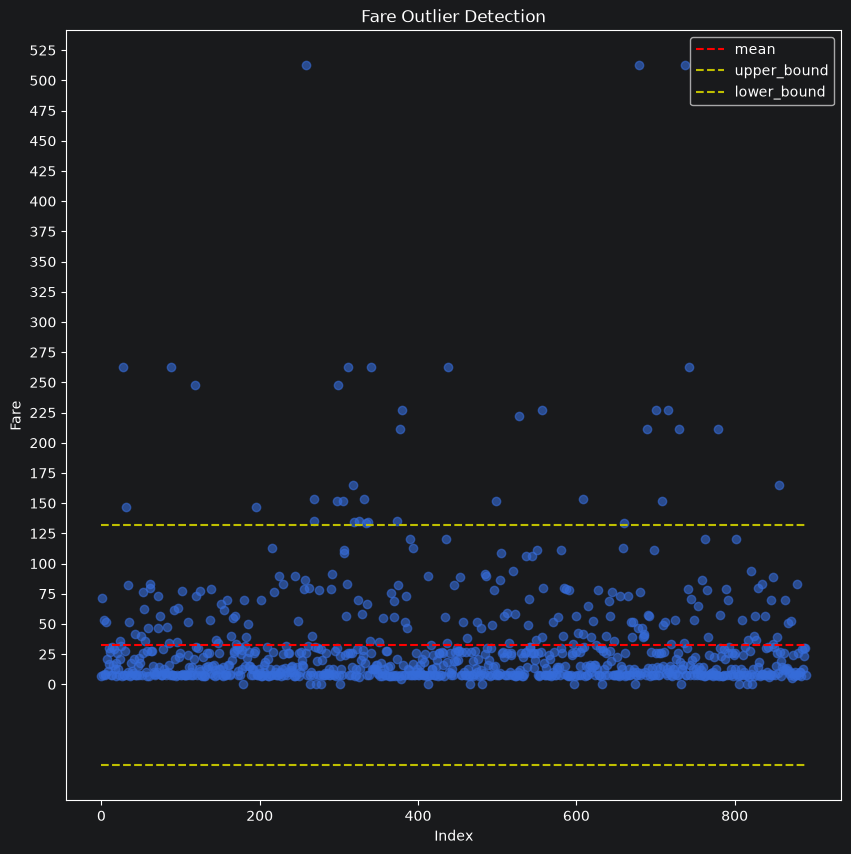

In [178]:
plt.figure(figsize=(10, 10))
plt.scatter(df.index, df.fare, alpha=0.6)
plt.yticks(range(0, 651, 25))
plt.hlines(mean, xmin=df.index.min(),
           xmax=df.index.max(), colors="r", linestyles="dashed", label="mean")

plt.hlines(upper_bound, xmin=df.index.min(),
           xmax=df.index.max(), colors="y", linestyles="dashed", label="upper_bound")

plt.hlines(lower_bound, xmin=df.index.min(),
           xmax=df.index.max(), colors="y", linestyles="dashed", label="lower_bound")

plt.title("Fare Outlier Detection")
plt.xlabel("Index")
plt.ylabel("Fare")
plt.legend()
plt.show()


<div dir="rtl" style="
    text-align: right;
    font-size: 20px;
    line-height: 2;
    font-family: Tahoma;
">
بررسی تعداد بلیط های فروخته شده براساس بازه قیمتی
<div>

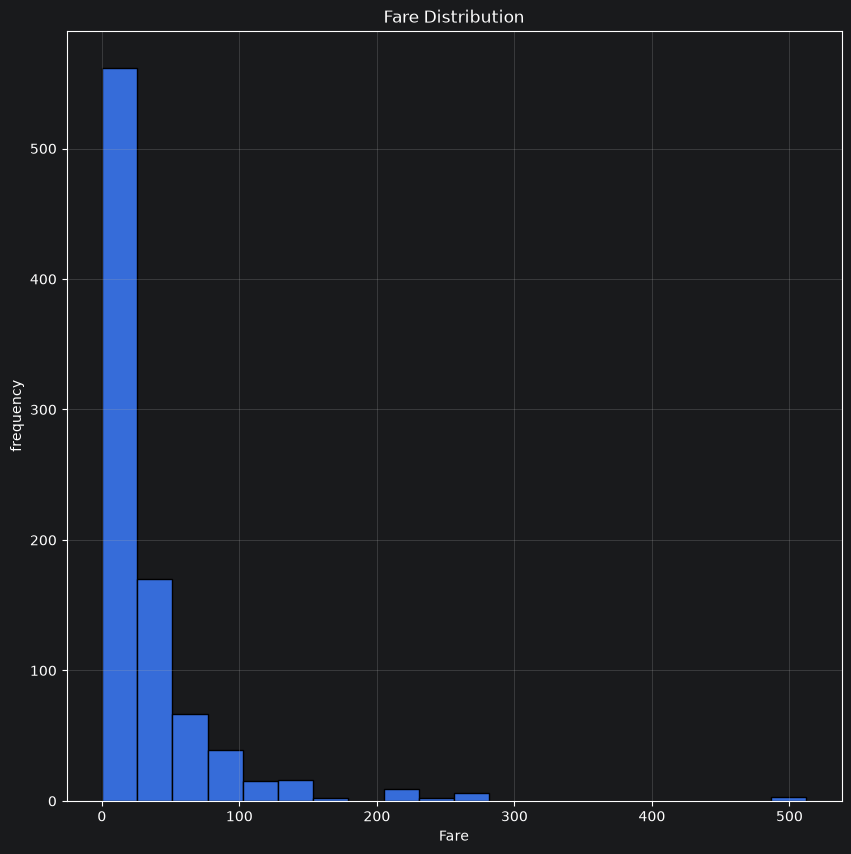

In [179]:
plt.figure(figsize=(10, 10))
plt.hist(df["fare"], bins=20, edgecolor="black")

plt.title("Fare Distribution")
plt.xlabel("Fare")
plt.ylabel("frequency")
plt.grid(alpha=0.3)
plt.show()


<div dir="rtl" style="
    text-align: right;
    font-size: 20px;
    line-height: 2;
    font-family: Tahoma;
">
بررسی قیمت بلیط بر اساس نجات پبدا کردن یا کشته شدن افراد
<div>

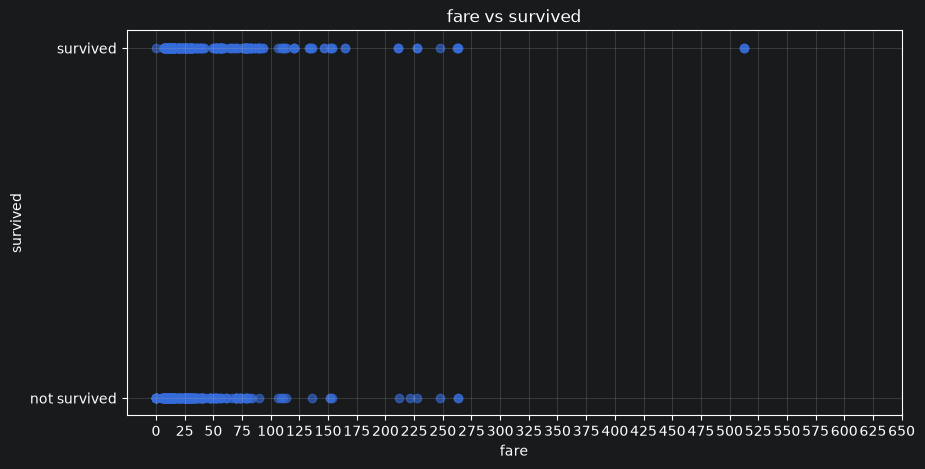

In [180]:
plt.figure(figsize=(10, 5))

plt.scatter(df["fare"], df["survived"], alpha=0.6)
plt.yticks([0, 1], ["not survived", "survived"])
plt.xticks(range(0, 651, 25))
plt.title("fare vs survived")
plt.xlabel("fare")
plt.ylabel("survived")
plt.grid(alpha=0.3)
plt.show()

<div dir="rtl" style="
    text-align: right;
    font-size: 20px;
    line-height: 2;
    font-family: Tahoma;
">
بررسی میانگین قیمت های بلیط مردان و زنان
<div>

In [181]:
male_fare = df[df["sex"] == "male"]["fare"]
female_fare = df[df["sex"] == "female"]["fare"]
male_fare.mean()
female_fare.mean()
print(f"male_fare:{male_fare.mean()}, female_fare:{female_fare.mean()}")


male_fare:25.523893414211443, female_fare:44.47981783439491


<div dir="rtl" style="
    text-align: right;
    font-size: 20px;
    line-height: 2;
    font-family: Tahoma;
">
بررسی قیمت بلیط ها بر اساس اندیس ها و رسم خطوط میانگین برای مردان و زنان
<div>

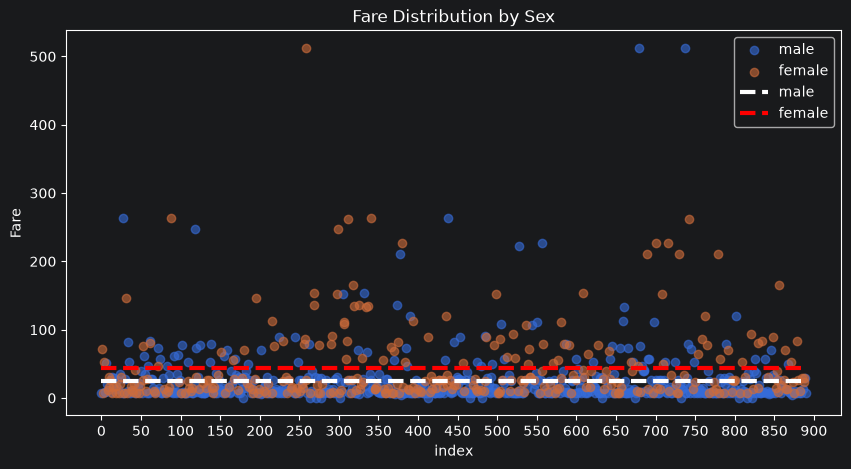

In [182]:
plt.figure(figsize=(10, 5))

plt.scatter(male_fare.index, male_fare, alpha=0.6, label="male")
plt.scatter(female_fare.index, female_fare, alpha=0.6, label="female")
plt.xticks(range(0, 901, 50))

plt.hlines(male_fare.mean(), xmax=df.index.max(), xmin=df.index.min(), colors="w", linestyles="dashed", label="male",
           linewidth=3, alpha=1)

plt.hlines(female_fare.mean(), xmax=df.index.max(), xmin=df.index.min(), colors="r", linestyles="dashed",
           label="female", linewidth=3, alpha=1)

plt.title("Fare Distribution by Sex")
plt.xlabel("index")
plt.ylabel("Fare")

plt.legend()
plt.show()




# Family Status

sibsp ===> تعداد همسر و خواهر و برادر همراه مسافر
|parch ===> تعداد والدین و فرزندان همراه مسافر

In [183]:
sibsp_count = df["sibsp"].value_counts()
parch_count = df["parch"].value_counts()

print(f"sibsp_count:{sibsp_count}\nparch_count:{parch_count}")

sibsp_count:sibsp
0    608
1    209
2     28
4     18
3     16
8      7
5      5
Name: count, dtype: int64
parch_count:parch
0    678
1    118
2     80
5      5
3      5
4      4
6      1
Name: count, dtype: int64


In [184]:
df["family_count"] = df["sibsp"] + df["parch"]

print(df["family_count"])

0      1
1      1
2      0
3      1
4      0
      ..
886    0
887    0
888    3
889    0
890    0
Name: family_count, Length: 891, dtype: int64


# class

In [185]:
class_count = df["pclass"].value_counts()
class_count

pclass
3    491
1    216
2    184
Name: count, dtype: int64

# who

In [186]:
who_count = df["who"].value_counts()
who_count

who
man      537
woman    271
child     83
Name: count, dtype: int64

In [187]:
who_survival = [
 df[df["who"] == "man"]["survived"].mean() * 100,
 df[df["who"] == "woman"]["survived"].mean() * 100,
 df[df["who"] == "child"]["survived"].mean() * 100
]
print(f"man survival:{man_survival}\n,woman survival:{woman_survival}\n,child_survival:{child_survival}")

man survival:16.387337057728118
,woman survival:75.64575645756457
,child_survival:59.036144578313255


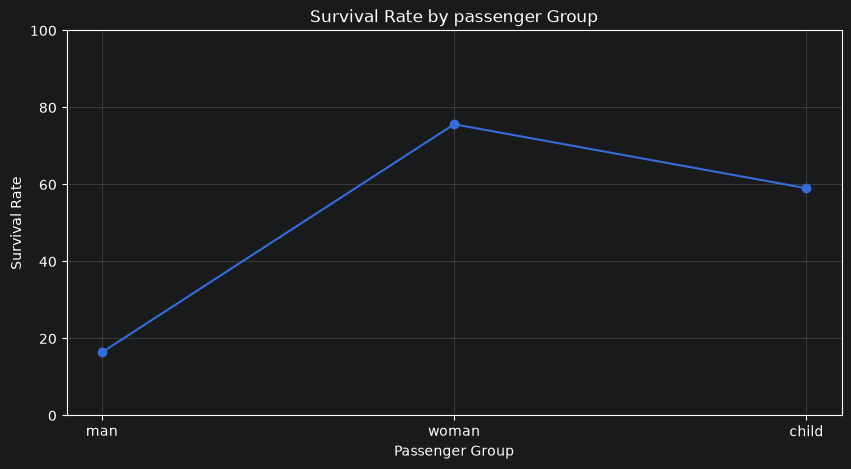

In [188]:
plt.figure(figsize=(10, 5))
plt.plot(["man", "woman", "child"], who_survival,marker="o")
plt.title("Survival Rate by passenger Group")
plt.xlabel("Passenger Group")
plt.ylabel("Survival Rate")
plt.ylim(0,100)
plt.grid(alpha=0.3)
plt.show()